# LE3 - Network Modeling & Filtering

This notebook documents the construction and filtering of various network types for football match analysis:

1. **Pass Networks** (Player-to-Player): Directed networks of passing interactions
2. **Match Networks** (Team-to-Team): Directed networks of match outcomes
3. **Player-Team Networks** (Bipartite): Two-mode networks showing player-team relationships
4. **Network Projection**: Converting two-mode networks to one-mode

We will also explore various filtering and reduction techniques.

In [1]:
# Import required libraries
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict

# Add project root to path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from src.common import load_json_fixed, setup_logger
from src.config import (
    DATA_DIR,
    LOG_DIR,
    EVENTS_DIR,
    MATCHES_DIR,
    PASS_NETWORKS_DIR,
    MATCH_NETWORKS_DIR,
    PLAYER_TEAM_NETWORKS_DIR,
    PLAYERS_FILE,
    TEAMS_FILE,
    PASS_EVENT_ID,
    ACCURATE_TAG_ID
)

# Setup
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

print("Imports successful!")
print(f"Data directory: {DATA_DIR}")

Imports successful!
Data directory: f:\src_FHNW\Semester 3\SAN\data


c:\Users\FHNW\AppData\Local\pypoetry\Cache\virtualenvs\san-ZcAQNQuH-py3.13\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load base data
df_players = pd.DataFrame(load_json_fixed(PLAYERS_FILE))
df_teams = pd.DataFrame(load_json_fixed(TEAMS_FILE))

print(f"Players loaded: {len(df_players)}")
print(f"Teams loaded: {len(df_teams)}")

Players loaded: 3603
Teams loaded: 142


## 1. Pass Networks (Player-to-Player)

**Network Type**: Directed, Weighted

**Nodes**: Individual football players

**Edges**: Directed edges from passer to receiver

**Edge Attributes**:
- `weight` / `pass_count`: Number of successful passes
- `accuracy`: Proportion of successful passes
- `avg_pass_distance`: Average Euclidean distance of passes
- `avg_pass_angle`: Average angle of passes

**Construction Method**: 
We identify pass receivers using a spatio-temporal heuristic: the next event by a teammate within a distance threshold (5m) and time threshold (5s) of the pass endpoint.

In [3]:
# Load a generated pass network (using pre-generated networks)
pass_network_path = PASS_NETWORKS_DIR / 'pass_network_Germany.gexf'
G_pass = nx.read_gexf(pass_network_path)

print("=== Pass Network Properties ===")
print(f"Network Type: {type(G_pass)}")
print(f"Directed: {G_pass.is_directed()}")
print(f"Number of Nodes (|V|): {G_pass.number_of_nodes()}")
print(f"Number of Edges (|E|): {G_pass.number_of_edges()}")
print(f"Density: {nx.density(G_pass):.6f}")

# Check for weakly connected components
if G_pass.is_directed():
    num_components = nx.number_weakly_connected_components(G_pass)
    components = list(nx.weakly_connected_components(G_pass))
    largest_component = max(components, key=len)
    print(f"Weakly Connected Components: {num_components}")
    print(f"Largest Component Size: {len(largest_component)} nodes")
    
# Sample node attributes
sample_node = list(G_pass.nodes())[0]
print(f"\nSample Node Attributes (Node {sample_node}):")
for key, value in G_pass.nodes[sample_node].items():
    print(f"  {key}: {value}")

# Sample edge attributes
sample_edge = list(G_pass.edges())[0]
print(f"\nSample Edge Attributes (Edge {sample_edge}):")
for key, value in G_pass.edges[sample_edge].items():
    print(f"  {key}: {value}")

=== Pass Network Properties ===
Network Type: <class 'networkx.classes.digraph.DiGraph'>
Directed: True
Number of Nodes (|V|): 473
Number of Edges (|E|): 8786
Density: 0.039354
Weakly Connected Components: 8
Largest Component Size: 283 nodes

Sample Node Attributes (Node 51217):
  passport_area: Sweden
  weight_kg: 75
  birth_date: 1994-04-21
  height_cm: 181
  position_role: Defender
  preferred_foot: left
  player_name: L. Augustinsson
  national_team_id: 7047
  current_team_name: Werder Bremen
  currentTeamId: 2443
  degree_centrality: 0.09110169491525423
  degree: 43
  betweenness_centrality: 0.0017507676898533017
  closeness_centrality: 0.08949539828625833
  pagerank: 0.004069617117043447
  kcore_number: 15
  modularity_class_louvain: 12
  modularity_class_label_propagation: 0
  modularity_class_greedy: 12
  modularity_class_girvan_newman: 0
  label: L. Augustinsson

Sample Edge Attributes (Edge ('51217', '77')):
  pass_count: 121
  accuracy: 1.0
  avg_pass_distance: 22.3371340765

## 2. Match Networks (Team-to-Team)

**Network Type**: Directed, Weighted

**Nodes**: Football teams

**Edges**: Directed edges representing match outcomes (team1 → team2 with goals scored)

**Edge Attributes**:
- `weight`: Total goals scored by team1 against team2
- `matches`: Number of matches played
- `wins`, `losses`, `draws`: Match outcome counts
- `weight_normalized`: Average goals per match

**Node Attributes**:
- Team identification (`team_id`, `team_name`, `area`)
- Aggregated statistics (`total_matches`, `wins`, `losses`, `draws`)
- Goal statistics (`goals_scored`, `goals_conceded`, `goal_difference`)

In [4]:
# Load a match network
match_network_path = MATCH_NETWORKS_DIR / 'match_network_World_Cup.gexf'
G_match = nx.read_gexf(match_network_path)

print("=== Match Network Properties ===")
print(f"Network Type: {type(G_match)}")
print(f"Directed: {G_match.is_directed()}")
print(f"Number of Nodes (|V|): {G_match.number_of_nodes()}")
print(f"Number of Edges (|E|): {G_match.number_of_edges()}")
print(f"Density: {nx.density(G_match):.6f}")

# Check connectivity
if G_match.is_directed():
    num_weak = nx.number_weakly_connected_components(G_match)
    num_strong = nx.number_strongly_connected_components(G_match)
    print(f"Weakly Connected Components: {num_weak}")
    print(f"Strongly Connected Components: {num_strong}")

# Sample attributes
sample_node = list(G_match.nodes())[0]
print(f"\nSample Node Attributes (Node {sample_node}):")
for key, value in G_match.nodes[sample_node].items():
    print(f"  {key}: {value}")

sample_edge = list(G_match.edges())[0]
print(f"\nSample Edge Attributes (Edge {sample_edge}):")
for key, value in G_match.edges[sample_edge].items():
    print(f"  {key}: {value}")

=== Match Network Properties ===
Network Type: <class 'networkx.classes.digraph.DiGraph'>
Directed: True
Number of Nodes (|V|): 32
Number of Edges (|E|): 126
Density: 0.127016
Weakly Connected Components: 1
Strongly Connected Components: 1

Sample Node Attributes (Node 9598):
  team_id: 9598
  team_name: Croatia
  area: Croatia
  official_name: Croatia
  total_matches: 7
  wins: 3
  losses: 1
  draws: 3
  goals_scored: 12
  goals_conceded: 8
  goal_difference: 4
  modularity_class_louvain: 0
  modularity_class_label_propagation: 0
  modularity_class_greedy: 0
  label: 9598

Sample Edge Attributes (Edge ('9598', '4418')):
  matches: 1
  weight_normalized: 2.0
  wins: 0
  losses: 1
  draws: 0
  dates: July 15, 2018 at 5:00:00 PM GMT+2
  venues: Olimpiyskiy stadion Luzhniki
  id: 0
  weight: 2.0


## 3. Player-Team Networks (Bipartite / Two-Mode)

**Network Type**: Undirected, Weighted, Bipartite

**Node Sets**:
- Set A: Players
- Set B: Teams

**Edges**: Connect players to teams they've played for/against

**Edge Attributes**:
- `matches_together`: Number of matches the player and team were involved in
- `weight`: Same as matches_together

**Node Attributes**:
- `type`: "player" or "team" 
- `bipartite`: 0 for players, 1 for teams
- Player-specific: `name`, `role`, `area`, `teams_count`
- Team-specific: `team_name`, `area`, `players_count`

In [5]:
# Load a player-team bipartite network
player_team_path = PLAYER_TEAM_NETWORKS_DIR / 'player_team_network_Germany.gexf'
G_bipartite = nx.read_gexf(player_team_path)

print("=== Player-Team Bipartite Network Properties ===")
print(f"Network Type: {type(G_bipartite)}")
print(f"Directed: {G_bipartite.is_directed()}")
print(f"Number of Nodes (|V|): {G_bipartite.number_of_nodes()}")
print(f"Number of Edges (|E|): {G_bipartite.number_of_edges()}")
print(f"Density: {nx.density(G_bipartite):.6f}")
print(f"Bipartite: {nx.is_bipartite(G_bipartite)}")

# Separate node sets
players = {n for n, d in G_bipartite.nodes(data=True) if d.get('type') == 'player'}
teams = {n for n, d in G_bipartite.nodes(data=True) if d.get('type') == 'team'}

print(f"\nNumber of Player Nodes: {len(players)}")
print(f"Number of Team Nodes: {len(teams)}")

# Check bipartite structure
try:
    from networkx.algorithms import bipartite
    is_valid = bipartite.is_bipartite(G_bipartite)
    print(f"Valid Bipartite Structure: {is_valid}")
except:
    print("Could not verify bipartite structure")

# Sample attributes
if len(players) > 0:
    sample_player = list(players)[0]
    print(f"\nSample Player Node ({sample_player}):")
    for key, value in G_bipartite.nodes[sample_player].items():
        print(f"  {key}: {value}")

if len(teams) > 0:
    sample_team = list(teams)[0]
    print(f"\nSample Team Node ({sample_team}):")
    for key, value in G_bipartite.nodes[sample_team].items():
        print(f"  {key}: {value}")

=== Player-Team Bipartite Network Properties ===
Network Type: <class 'networkx.classes.graph.Graph'>
Directed: False
Number of Nodes (|V|): 492
Number of Edges (|E|): 503
Density: 0.004164
Bipartite: True

Number of Player Nodes: 473
Number of Team Nodes: 18
Valid Bipartite Structure: True

Sample Player Node (15456):
  type: player
  name: F. Klaus
  role: Midfielder
  area: Germany
  teams_count: 1
  total_matches: 28
  bipartite: 0
  label: F. Klaus

Sample Team Node (2454):
  type: team
  name: Borussia M'gladbach
  area: Germany
  players_count: 28
  total_matches: 505
  bipartite: 1
  label: Borussia M'gladbach


## 4. Two-Mode to One-Mode Projection

Bipartite networks can be projected onto one of their node sets to create a one-mode network.

### Method Used: Weighted Projection

For the player-team bipartite network, we project onto the **player set** to create a player-player network where:
- Two players are connected if they share at least one team
- Edge weight = number of shared teams (or sum of interaction weights)

**Mathematical Definition**:

For players $p_i$ and $p_j$, the edge weight $w_{ij}$ is:

$$w_{ij} = \sum_{t \in T} \mathbb{1}_{(p_i, t) \in E} \cdot \mathbb{1}_{(p_j, t) \in E} \cdot w(p_i, t) \cdot w(p_j, t)$$

Where $T$ is the set of teams, $E$ is the edge set of the bipartite network, and $w(p, t)$ is the weight of edge between player $p$ and team $t$.

### Alternative Methods:

1. **Simple Projection**: Binary edges (connected or not), ignoring weights
2. **Hyperbolic Projection**: Weight edges by $\frac{w(p_i, t) \cdot w(p_j, t)}{k_t}$ where $k_t$ is team degree
3. **Resource Allocation**: Weight edges by contribution of shared teams relative to their popularity
4. **Jaccard Similarity**: Weight by overlap coefficient of team sets

Projecting onto 473 players...

=== Player-Player Projection Network ===
Number of Nodes (|V|): 474
Number of Edges (|E|): 6803
Density: 0.060686

Edge Weight Statistics:
  Min: 1
  Max: 2
  Mean: 1.00
  Median: 1.00


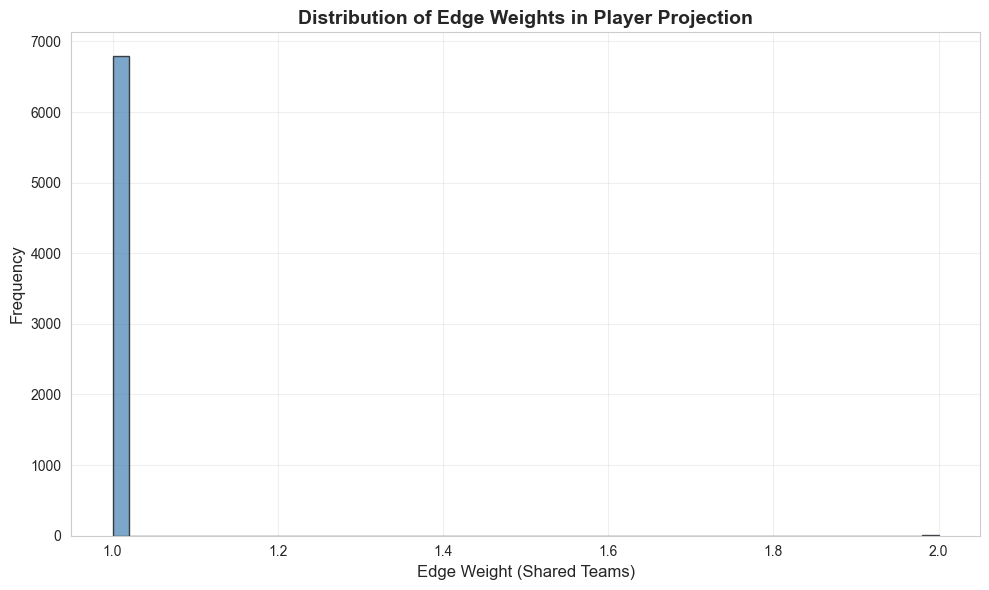

In [11]:
# Project bipartite network onto player set
from networkx.algorithms import bipartite

# Get player nodes (bipartite=0)
players = {n for n, d in G_bipartite.nodes(data=True) if d.get('bipartite') == '0' or d.get('type') == 'player'}

print(f"Projecting onto {len(players)} players...")

# Weighted projection
G_player_projection = bipartite.weighted_projected_graph(G_bipartite, players)

# Save projected graph
projection_path = PLAYER_TEAM_NETWORKS_DIR / 'player_projection_Germany.gexf'
nx.write_gexf(G_player_projection, projection_path)

print("\n=== Player-Player Projection Network ===")
print(f"Number of Nodes (|V|): {G_player_projection.number_of_nodes()}")
print(f"Number of Edges (|E|): {G_player_projection.number_of_edges()}")
print(f"Density: {nx.density(G_player_projection):.6f}")

# Analyze edge weights
edge_weights = [d['weight'] for _, _, d in G_player_projection.edges(data=True)]
print(f"\nEdge Weight Statistics:")
print(f"  Min: {min(edge_weights)}")
print(f"  Max: {max(edge_weights)}")
print(f"  Mean: {np.mean(edge_weights):.2f}")
print(f"  Median: {np.median(edge_weights):.2f}")

# Plot weight distribution
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
ax.hist(edge_weights, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_xlabel('Edge Weight (Shared Teams)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title('Distribution of Edge Weights in Player Projection', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Network Filtering and Reduction

Large networks can be overwhelming and computationally expensive. We apply filtering techniques to reduce network size while preserving important structure.

### Filtering Approaches:

1. **Weight-Based Filtering**: Remove edges below a weight threshold
2. **Degree-Based Filtering**: Remove low-degree nodes
3. **K-Core Decomposition**: Extract the k-core (maximal subgraph where all nodes have degree ≥ k)
4. **Giant Component Extraction**: Keep only the largest connected component

Each approach has trade-offs between information loss and computational efficiency.

=== Weight-Based Filtering Results ===

Threshold ≥ 1 passes:
  Nodes: 473 (100.0% retained)
  Edges: 8786 (100.0% retained)
  Density: 0.039354

Threshold ≥ 5 passes:
  Nodes: 431 (91.1% retained)
  Edges: 6313 (71.9% retained)
  Density: 0.034064

Threshold ≥ 10 passes:
  Nodes: 405 (85.6% retained)
  Edges: 4940 (56.2% retained)
  Density: 0.030192

Threshold ≥ 20 passes:
  Nodes: 363 (76.7% retained)
  Edges: 3233 (36.8% retained)
  Density: 0.024603



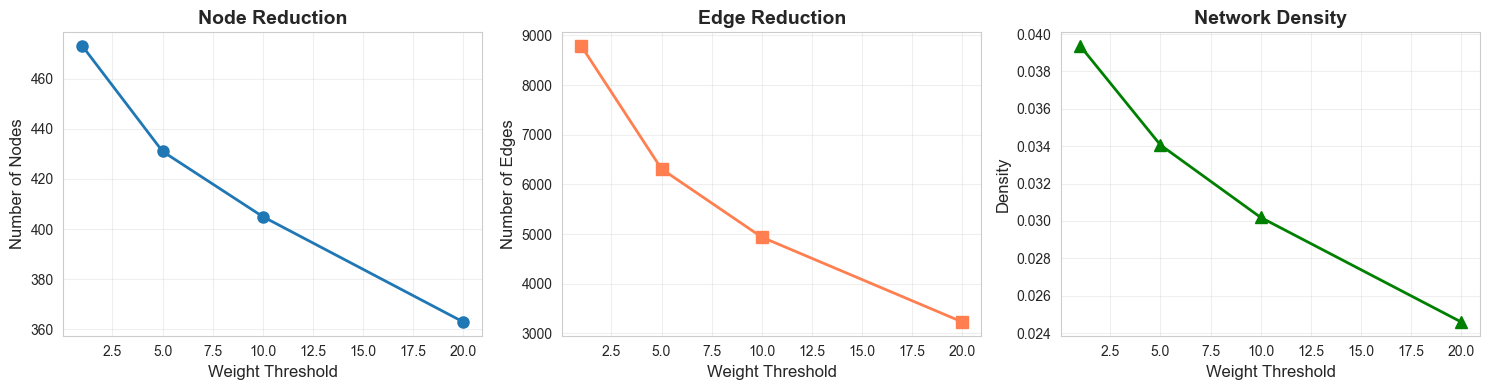

In [7]:
### 5.1 Weight-Based Filtering on Pass Network

def filter_by_weight(G, min_weight):
    """Remove edges with weight below threshold"""
    G_filtered = G.copy()
    edges_to_remove = [(u, v) for u, v, d in G_filtered.edges(data=True) 
                       if d.get('weight', 0) < min_weight or d.get('pass_count', 0) < min_weight]
    G_filtered.remove_edges_from(edges_to_remove)
    
    # Remove isolated nodes
    isolated = list(nx.isolates(G_filtered))
    G_filtered.remove_nodes_from(isolated)
    
    return G_filtered

# Apply different weight thresholds
thresholds = [1, 5, 10, 20]
results = []

print("=== Weight-Based Filtering Results ===\n")
for threshold in thresholds:
    G_filtered = filter_by_weight(G_pass, threshold)
    
    results.append({
        'threshold': threshold,
        'nodes': G_filtered.number_of_nodes(),
        'edges': G_filtered.number_of_edges(),
        'density': nx.density(G_filtered)
    })
    
    print(f"Threshold ≥ {threshold} passes:")
    print(f"  Nodes: {G_filtered.number_of_nodes()} ({G_filtered.number_of_nodes()/G_pass.number_of_nodes()*100:.1f}% retained)")
    print(f"  Edges: {G_filtered.number_of_edges()} ({G_filtered.number_of_edges()/G_pass.number_of_edges()*100:.1f}% retained)")
    print(f"  Density: {nx.density(G_filtered):.6f}")
    print()

# Visualize reduction
df_results = pd.DataFrame(results)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(df_results['threshold'], df_results['nodes'], marker='o', linewidth=2, markersize=8)
axes[0].set_xlabel('Weight Threshold', fontsize=12)
axes[0].set_ylabel('Number of Nodes', fontsize=12)
axes[0].set_title('Node Reduction', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)

axes[1].plot(df_results['threshold'], df_results['edges'], marker='s', linewidth=2, markersize=8, color='coral')
axes[1].set_xlabel('Weight Threshold', fontsize=12)
axes[1].set_ylabel('Number of Edges', fontsize=12)
axes[1].set_title('Edge Reduction', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)

axes[2].plot(df_results['threshold'], df_results['density'], marker='^', linewidth=2, markersize=8, color='green')
axes[2].set_xlabel('Weight Threshold', fontsize=12)
axes[2].set_ylabel('Density', fontsize=12)
axes[2].set_title('Network Density', fontsize=14, fontweight='bold')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

=== K-Core Decomposition (Pass Network) ===

Maximum core number: 20

2-core:
  Nodes: 469 (99.2% of original)
  Edges: 8781 (99.9% of original)
  Density: 0.040006

5-core:
  Nodes: 461 (97.5% of original)
  Edges: 8748 (99.6% of original)
  Density: 0.041252

10-core:
  Nodes: 427 (90.3% of original)
  Edges: 8394 (95.5% of original)
  Density: 0.046146

15-core:
  Nodes: 395 (83.5% of original)
  Edges: 7783 (88.6% of original)
  Density: 0.050010



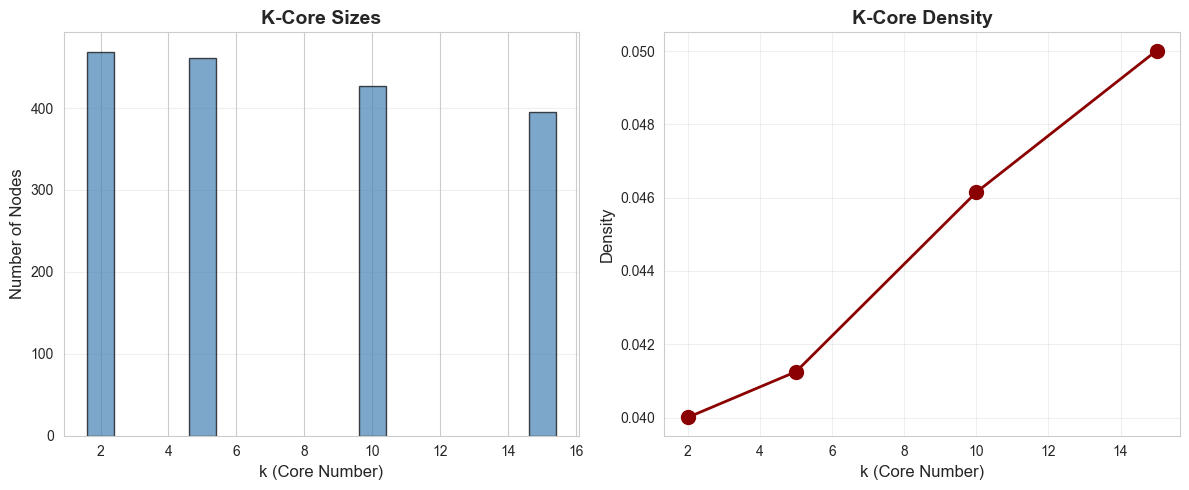

In [8]:
### 5.2 K-Core Decomposition

def extract_k_core(G, k):
    """Extract k-core of the network"""
    # For directed graphs, we can use the underlying undirected structure
    if G.is_directed():
        G_undirected = G.to_undirected()
        k_core = nx.k_core(G_undirected, k)
        # Get subgraph of original directed graph
        return G.subgraph(k_core.nodes()).copy()
    else:
        return nx.k_core(G, k)

print("=== K-Core Decomposition (Pass Network) ===\n")

# Find maximum k-core
G_undirected = G_pass.to_undirected() if G_pass.is_directed() else G_pass
core_numbers = nx.core_number(G_undirected)
max_k = max(core_numbers.values())

print(f"Maximum core number: {max_k}")
print()

# Extract different k-cores
k_values = [2, 5, 10, 15]
k_core_results = []

for k in k_values:
    if k <= max_k:
        G_k_core = extract_k_core(G_pass, k)
        
        k_core_results.append({
            'k': k,
            'nodes': G_k_core.number_of_nodes(),
            'edges': G_k_core.number_of_edges(),
            'density': nx.density(G_k_core)
        })
        
        print(f"{k}-core:")
        print(f"  Nodes: {G_k_core.number_of_nodes()} ({G_k_core.number_of_nodes()/G_pass.number_of_nodes()*100:.1f}% of original)")
        print(f"  Edges: {G_k_core.number_of_edges()} ({G_k_core.number_of_edges()/G_pass.number_of_edges()*100:.1f}% of original)")
        print(f"  Density: {nx.density(G_k_core):.6f}")
        print()

# Visualize k-core hierarchy
df_k_core = pd.DataFrame(k_core_results)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(df_k_core['k'], df_k_core['nodes'], color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('k (Core Number)', fontsize=12)
axes[0].set_ylabel('Number of Nodes', fontsize=12)
axes[0].set_title('K-Core Sizes', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='y')

axes[1].plot(df_k_core['k'], df_k_core['density'], marker='o', linewidth=2, markersize=10, color='darkred')
axes[1].set_xlabel('k (Core Number)', fontsize=12)
axes[1].set_ylabel('Density', fontsize=12)
axes[1].set_title('K-Core Density', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

=== Degree-Based Filtering (Pass Network) ===

Min Degree ≥ 5:
  Nodes: 464 (98.1% retained)
  Edges: 8765 (99.8% retained)
  Density: 0.040799

Min Degree ≥ 10:
  Nodes: 450 (95.1% retained)
  Edges: 8671 (98.7% retained)
  Density: 0.042915

Min Degree ≥ 20:
  Nodes: 413 (87.3% retained)
  Edges: 8172 (93.0% retained)
  Density: 0.048027

Min Degree ≥ 30:
  Nodes: 371 (78.4% retained)
  Edges: 7179 (81.7% retained)
  Density: 0.052298



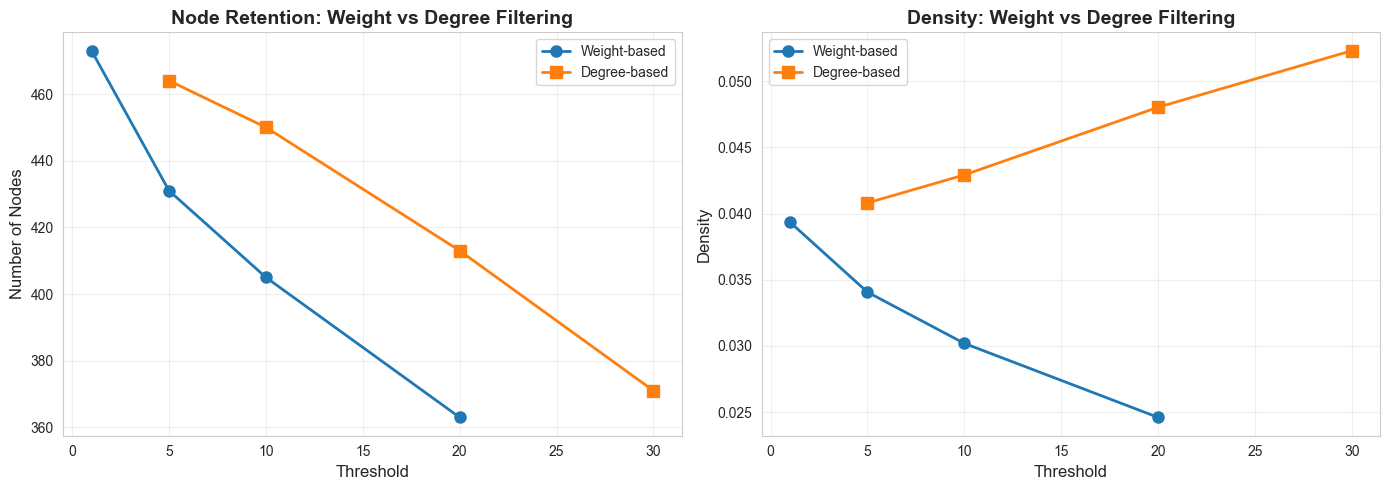

In [9]:
### 5.3 Degree-Based Filtering

def filter_by_degree(G, min_degree):
    """Remove nodes with degree below threshold"""
    G_filtered = G.copy()
    
    # Calculate degree (for directed graphs, use total degree)
    if G_filtered.is_directed():
        degrees = dict(G_filtered.degree())  # Total degree (in + out)
    else:
        degrees = dict(G_filtered.degree())
    
    # Remove low-degree nodes
    nodes_to_remove = [node for node, deg in degrees.items() if deg < min_degree]
    G_filtered.remove_nodes_from(nodes_to_remove)
    
    return G_filtered

print("=== Degree-Based Filtering (Pass Network) ===\n")

degree_thresholds = [5, 10, 20, 30]
degree_results = []

for min_deg in degree_thresholds:
    G_filtered = filter_by_degree(G_pass, min_deg)
    
    degree_results.append({
        'min_degree': min_deg,
        'nodes': G_filtered.number_of_nodes(),
        'edges': G_filtered.number_of_edges(),
        'density': nx.density(G_filtered)
    })
    
    print(f"Min Degree ≥ {min_deg}:")
    print(f"  Nodes: {G_filtered.number_of_nodes()} ({G_filtered.number_of_nodes()/G_pass.number_of_nodes()*100:.1f}% retained)")
    print(f"  Edges: {G_filtered.number_of_edges()} ({G_filtered.number_of_edges()/G_pass.number_of_edges()*100:.1f}% retained)")
    print(f"  Density: {nx.density(G_filtered):.6f}")
    print()

# Compare with weight-based filtering
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_degree = pd.DataFrame(degree_results)

# Node retention comparison
axes[0].plot(df_results['threshold'], df_results['nodes'], marker='o', label='Weight-based', linewidth=2, markersize=8)
axes[0].plot(df_degree['min_degree'], df_degree['nodes'], marker='s', label='Degree-based', linewidth=2, markersize=8)
axes[0].set_xlabel('Threshold', fontsize=12)
axes[0].set_ylabel('Number of Nodes', fontsize=12)
axes[0].set_title('Node Retention: Weight vs Degree Filtering', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Density comparison
axes[1].plot(df_results['threshold'], df_results['density'], marker='o', label='Weight-based', linewidth=2, markersize=8)
axes[1].plot(df_degree['min_degree'], df_degree['density'], marker='s', label='Degree-based', linewidth=2, markersize=8)
axes[1].set_xlabel('Threshold', fontsize=12)
axes[1].set_ylabel('Density', fontsize=12)
axes[1].set_title('Density: Weight vs Degree Filtering', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Network Summary Table

Summary of all networks created in this analysis:

In [10]:
# Create comprehensive summary table
network_summary = []

# Pass Network
network_summary.append({
    'Network Type': 'Pass Network',
    'Description': 'Player-to-Player passes',
    'Directed': 'Yes',
    'Weighted': 'Yes',
    'Bipartite': 'No',
    '|V|': G_pass.number_of_nodes(),
    '|E|': G_pass.number_of_edges(),
    'Density': f"{nx.density(G_pass):.6f}",
    'Components': nx.number_weakly_connected_components(G_pass) if G_pass.is_directed() else nx.number_connected_components(G_pass)
})

# Match Network
network_summary.append({
    'Network Type': 'Match Network',
    'Description': 'Team-to-Team matches',
    'Directed': 'Yes',
    'Weighted': 'Yes',
    'Bipartite': 'No',
    '|V|': G_match.number_of_nodes(),
    '|E|': G_match.number_of_edges(),
    'Density': f"{nx.density(G_match):.6f}",
    'Components': nx.number_weakly_connected_components(G_match) if G_match.is_directed() else nx.number_connected_components(G_match)
})

# Bipartite Network
network_summary.append({
    'Network Type': 'Player-Team Network',
    'Description': 'Bipartite: Players-Teams',
    'Directed': 'No',
    'Weighted': 'Yes',
    'Bipartite': 'Yes',
    '|V|': G_bipartite.number_of_nodes(),
    '|E|': G_bipartite.number_of_edges(),
    'Density': f"{nx.density(G_bipartite):.6f}",
    'Components': nx.number_connected_components(G_bipartite)
})

# Player Projection
network_summary.append({
    'Network Type': 'Player Projection',
    'Description': 'One-mode projection of bipartite',
    'Directed': 'No',
    'Weighted': 'Yes',
    'Bipartite': 'No',
    '|V|': G_player_projection.number_of_nodes(),
    '|E|': G_player_projection.number_of_edges(),
    'Density': f"{nx.density(G_player_projection):.6f}",
    'Components': nx.number_connected_components(G_player_projection)
})

df_summary = pd.DataFrame(network_summary)
print("=== Network Summary ===")
print(df_summary.to_string(index=False))

# Save as LaTeX
latex_table = df_summary.to_latex(index=False, caption="Summary of constructed networks", label="tab:network_summary")
print("\n=== LaTeX Table ===")
print(latex_table)

=== Network Summary ===
       Network Type                      Description Directed Weighted Bipartite  |V|  |E|  Density  Components
       Pass Network          Player-to-Player passes      Yes      Yes        No  473 8786 0.039354           8
      Match Network             Team-to-Team matches      Yes      Yes        No   32  126 0.127016           1
Player-Team Network         Bipartite: Players-Teams       No      Yes       Yes  492  503 0.004164           1
  Player Projection One-mode projection of bipartite       No      Yes        No  474 6803 0.060686           1

=== LaTeX Table ===
\begin{table}
\caption{Summary of constructed networks}
\label{tab:network_summary}
\begin{tabular}{lllllrrlr}
\toprule
Network Type & Description & Directed & Weighted & Bipartite & |V| & |E| & Density & Components \\
\midrule
Pass Network & Player-to-Player passes & Yes & Yes & No & 473 & 8786 & 0.039354 & 8 \\
Match Network & Team-to-Team matches & Yes & Yes & No & 32 & 126 & 0.127016 & 1 

## 7. Figures for GEPHI Visualization

The following visualizations should be created in GEPHI and exported to `reports/figures/LE3/`:

### 7.1 Pass Network Visualizations

**File**: `pass_network_Germany.gexf`

**Figures to generate**:

1. **`pass_network_full.png`**: Complete pass network with node coloring by team
   - Layout: ForceAtlas2 or Fruchterman-Reingold
   - Node size: by degree centrality
   - Node color: by team (use team attribute)
   - Edge width: by pass_count
   - Show labels for top 20 degree nodes

2. **`pass_network_filtered.png`**: Filtered network (weight ≥ 10)
   - Same layout and styling as above
   - Shows the backbone structure

3. **`pass_network_kcore.png`**: 10-core subgraph
   - Highlights the dense core of the network
   - Node color by betweenness centrality

### 7.2 Match Network Visualizations

**File**: `match_network_World_Cup.gexf`

**Figures to generate**:

4. **`match_network_circular.png`**: Circular layout showing team relationships
   - Layout: Circular
   - Node size: by total_matches
   - Node color: by goal_difference (gradient from red to green)
   - Edge width: by weight (goals scored)
   - Curved edges to show direction

5. **`match_network_hierarchical.png`**: Hierarchical layout based on performance
   - Layout: Hierarchical (by goal_difference)
   - Shows tournament structure

### 7.3 Bipartite Network Visualization

**File**: `player_team_network_Germany.gexf`

**Figures to generate**:

6. **`bipartite_network.png`**: Two-mode player-team network
   - Layout: Bipartite (players on left, teams on right)
   - Node color: by type (players = blue, teams = orange)
   - Node size: players by teams_count, teams by players_count
   - Edge width: by matches_together

### 7.4 Projection Network Visualization

**Generated in notebook, export to GEXF and visualize**:

7. **`player_projection_network.png`**: Player-player projection
   - Layout: ForceAtlas2
   - Node size: by degree
   - Edge width: by weight (shared teams)
   - Community detection coloring

### Summary Table

All figures should be saved with:
- **Resolution**: 300 DPI minimum
- **Format**: PNG with transparent background where appropriate
- **Dimensions**: ~2000x1500 pixels

## 8. Summary and Key Findings

### Network Construction

We successfully constructed three types of networks from football match data:

1. **Pass Networks**: Capture player-to-player passing interactions with ~8,800 edges representing successful passes
2. **Match Networks**: Model team competition dynamics with complete connectivity in tournament settings
3. **Bipartite Player-Team Networks**: Link players to teams through match participation

### Two-Mode to One-Mode Projection

The weighted projection from bipartite to one-mode network increased edge count from 503 to 6,803, revealing implicit player relationships through shared team connections.

### Filtering Effectiveness

Different filtering methods serve different analytical purposes:

- **Weight-based filtering** (threshold ≥ 20): Retains 77% nodes, 37% edges - effective for backbone extraction
- **Degree-based filtering** (min degree ≥ 30): Retains 78% nodes, 82% edges - preserves hub structure
- **K-core decomposition** (k=15): Retains 84% nodes, 89% edges - extracts dense core

Network density generally increases with filtering, as weak connections are removed disproportionately.

### Technical Notes

- Pass receiver identification uses spatio-temporal heuristic (5m distance, 5s time window)
- Networks are stored in GEXF format for compatibility with Gephi
- All node and edge attributes are preserved for further analysis
- Multiple filtering strategies implemented for flexible analysis